#Trabajo Especial - Sistema con Operarios

###Investigadores:
- Lopez Victoria
- Ponce Gessi Tomás

###Resolución:

In [ ]:
from random import expovariate
import matplotlib.pyplot as plt
import numpy as np

def simular_supermercado(maquinas = 7, repuestos = 3, tecnicos = 1, tiempo_de_fallo = 1, tiempo_de_reparacion = 8):
  """
    maquinas = Cantidad de maquinas
    repuestos = Cantidad de repuestos
    tecnicos = Cantidad de tecnicos
    tiempo_de_fallo = Tiempo de falla de una maquina
    tiempo_de_reparacion = Tiempo de reparacion de una maquina
  """
  tiempo = 0 # Tiempo simulado
  maquinas_rotas = 0   # Cantidad de maquinas rotas

  # Simulacion de un evento de fallo de una maquina
  def simular_evento_de_fallo():
    return expovariate(lambd=tiempo_de_fallo * maquinas)

  # Simulacion de un evento de reparacion de una maquina
  def simular_evento_de_reparacion():
    return expovariate(lambd=tiempo_de_reparacion * min(maquinas_rotas, tecnicos))

  # Mientras haya mas repuestos que maquinas rotas
  while repuestos >= maquinas_rotas:
    if maquinas_rotas > 0:
      # Caso hay almenos una maquina rota, decidimos que ocurre antes, si una reparacion o otro fallo.
      # Notar que mientras la tasa de reparacion sea menor a la tasa de fallo en la mayoria de casos el
      # sistema eventualmente dejara de funcionar.
      tiempo_hasta_falla = simular_evento_de_fallo()
      tiempo_hasta_reparacion = simular_evento_de_reparacion()
      if tiempo_hasta_falla >= tiempo_hasta_reparacion:
        tiempo += tiempo_hasta_reparacion
        maquinas_rotas -= 1
      else:
        tiempo += tiempo_hasta_falla
        maquinas_rotas += 1
      continue
    # Caso no hay maquinas rotas. Simplemente simulamos un fallo
    tiempo += simular_evento_de_fallo()
    maquinas_rotas += 1
  return tiempo

print("Total de simulaciones por caso: 10000\n")

simulation = np.fromfunction(np.vectorize(lambda _: simular_supermercado()), (10000,))
one_tech_3_parts = {
    "data": simulation,
    "avg": np.average(simulation),
    "std": np.std(simulation)
}
print("======== 1 Operario (3 Repuestos) ========")
print(f"Tiempo medio de fallo del sistema: %.5f" % one_tech_3_parts["avg"])
print(f"Desviacion estandar: %.5f" % one_tech_3_parts["std"])

simulation = np.fromfunction(np.vectorize(lambda _: simular_supermercado(tecnicos=1, repuestos=4)), (10000,))
one_tech_4_parts = {
    "data": simulation,
    "avg": np.average(simulation),
    "std": np.std(simulation)
}
print("\n======== 1 Operario (4 Repuestos) ========")
print(f"Tiempo medio de fallo del sistema: %.5f" % one_tech_4_parts["avg"])
print(f"Desviacion estandar: %.5f" % one_tech_4_parts["std"])

simulation = np.fromfunction(np.vectorize(lambda _: simular_supermercado(tecnicos=2)), (10000,))
two_tech_3_parts = {
    "data": simulation,
    "avg": np.average(simulation),
    "std": np.std(simulation)
}
print("\n======== 2 Operarios (3 Repuestos) ========")
print(f"Tiempo medio de fallo del sistema: %.5f" % two_tech_3_parts["avg"])
print(f"Desviacion estandar: %.5f" % two_tech_3_parts["std"])



Total de simulaciones por caso: 10000

======== 1 Operario (3 Repuestos) ========
Tiempo medio de fallo del sistema: 1.65822
Desviacion estandar: 1.46083

======== 1 Operario (4 Repuestos) ========
Tiempo medio de fallo del sistema: 2.61297
Desviacion estandar: 2.26813

======== 2 Operarios (3 Repuestos) ========
Tiempo medio de fallo del sistema: 3.31949
Desviacion estandar: 3.18487


##Generacion de graficos

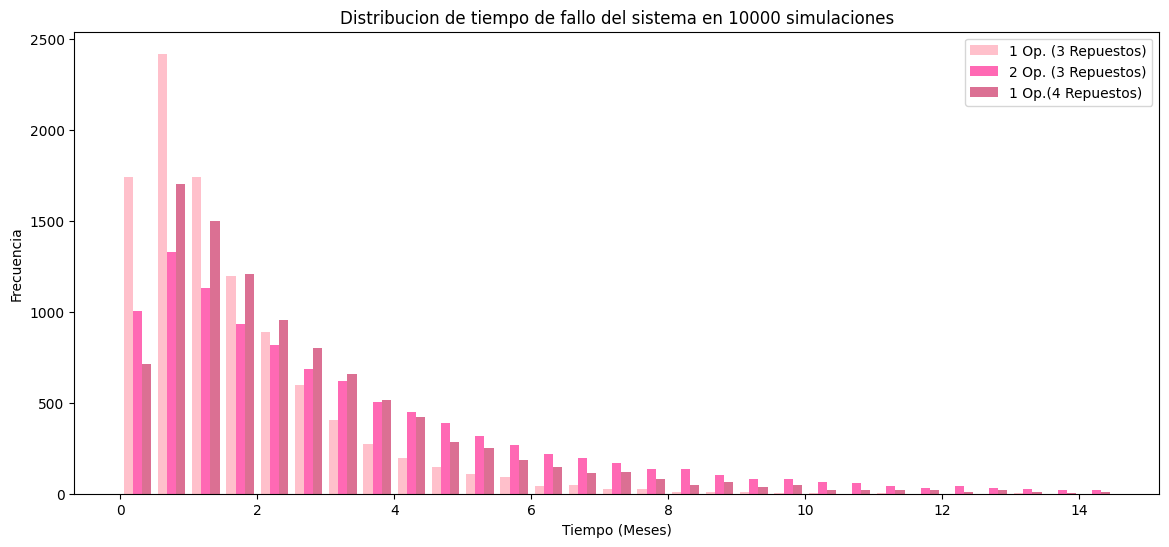

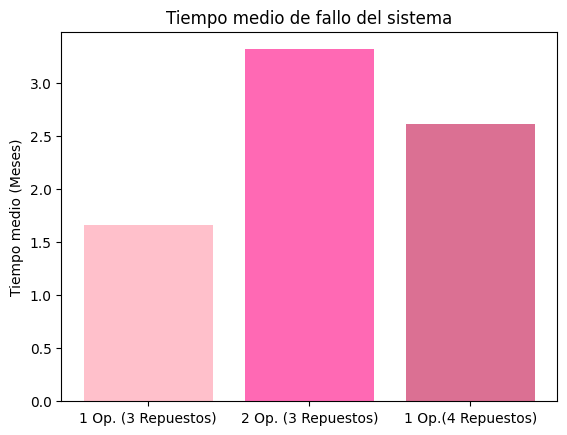

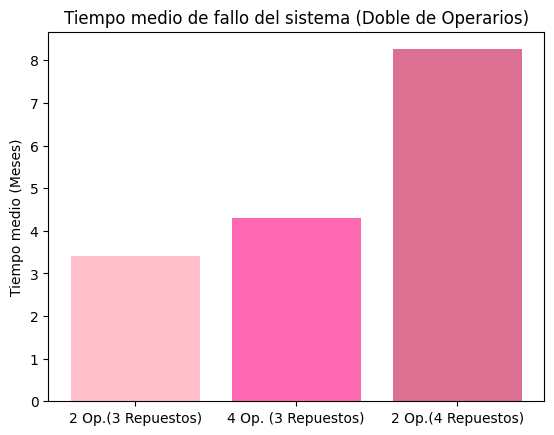

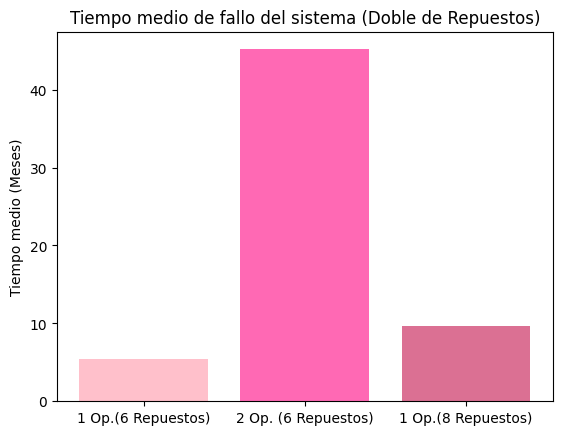

In [23]:

data = [one_tech_3_parts["data"], two_tech_3_parts["data"], one_tech_4_parts["data"]]
plt.figure(figsize=(14,6))
plt.hist(x=data, bins=[0] + [i / 2 for i in range(30)], label=["1 Op. (3 Repuestos)", "2 Op. (3 Repuestos)", "1 Op.(4 Repuestos)"], color=["#FFC0CB", "#FF69B4", "#DB7093"])
plt.legend()
plt.xlabel("Tiempo (Meses)")
plt.ylabel("Frecuencia")
plt.title("Distribucion de tiempo de fallo del sistema en 10000 simulaciones")
plt.show()


data = {
    "1 Op. (3 Repuestos)": one_tech_3_parts["avg"],
    "2 Op. (3 Repuestos)": two_tech_3_parts["avg"],
    "1 Op.(4 Repuestos)": one_tech_4_parts["avg"],
}
plt.bar(data.keys(), data.values(), color=["#FFC0CB", "#FF69B4", "#DB7093"], width=0.8)
plt.ylabel("Tiempo medio (Meses)")
plt.title("Tiempo medio de fallo del sistema")
plt.show()


data = {
    "2 Op.(3 Repuestos)": np.average(np.fromfunction(np.vectorize(lambda _: simular_supermercado(tecnicos=2)), (10000,))),
    "4 Op. (3 Repuestos)": np.average(np.fromfunction(np.vectorize(lambda _: simular_supermercado(tecnicos=4)), (10000,))),
    "2 Op.(4 Repuestos)": np.average(np.fromfunction(np.vectorize(lambda _: simular_supermercado(tecnicos=2, repuestos=4)), (10000,))),
}
plt.bar(data.keys(), data.values(), color=["#FFC0CB", "#FF69B4", "#DB7093"], width=0.8)
plt.ylabel("Tiempo medio (Meses)")
plt.title("Tiempo medio de fallo del sistema (Doble de Operarios)")
plt.show()


data = {
    "1 Op.(6 Repuestos)": np.average(np.fromfunction(np.vectorize(lambda _: simular_supermercado(tecnicos=1, repuestos=6)), (10000,))),
    "2 Op. (6 Repuestos)": np.average(np.fromfunction(np.vectorize(lambda _: simular_supermercado(tecnicos=2, repuestos=6)), (10000,))),
    "1 Op.(8 Repuestos)": np.average(np.fromfunction(np.vectorize(lambda _: simular_supermercado(tecnicos=1, repuestos=8)), (10000,))),
}
plt.bar(data.keys(), data.values(), color=["#FFC0CB", "#FF69B4", "#DB7093"], width=0.8)
plt.ylabel("Tiempo medio (Meses)")
plt.title("Tiempo medio de fallo del sistema (Doble de Repuestos)")
plt.show()